# Лабораторная работа №1. EDA - анализ данных об автомобилях

**Задача:** изучить характеристики подержанных автомобилей и их связь с ценой продажи `Selling_Price`. Данные: `car data.csv`.

Блокнот запускается из папки `eda` в VS Code. Датасет должен лежать в `data/car data.csv`.

## 1. Загрузка и знакомство с данными

Подключаем библиотеки и читаем файл. `pandas` нужен для таблиц, `matplotlib` - для обычных графиков, `plotly` - для интерактивного.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

# Код работает и из папки eda, и из корня проекта.
project_dir = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
data_dir = project_dir / "data"
eda_dir = project_dir / "eda"
eda_dir.mkdir(exist_ok=True)

df = pd.read_csv(data_dir / "car data.csv")
print("Размер датасета:", df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


Размер датасета: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [2]:
# Список столбцов и типы данных
print(df.dtypes)
print("Количество строк:", len(df))

Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Driven_kms         int64
Fuel_Type         object
Selling_type      object
Transmission      object
Owner              int64
dtype: object
Количество строк: 301


In [3]:
# Числовые статистики
print(df.describe())

              Year  Selling_Price  Present_Price     Driven_kms       Owner
count   301.000000     301.000000     301.000000     301.000000  301.000000
mean   2013.627907       4.661296       7.628472   36947.205980    0.043189
std       2.891554       5.082812       8.642584   38886.883882    0.247915
min    2003.000000       0.100000       0.320000     500.000000    0.000000
25%    2012.000000       0.900000       1.200000   15000.000000    0.000000
50%    2014.000000       3.600000       6.400000   32000.000000    0.000000
75%    2016.000000       6.000000       9.900000   48767.000000    0.000000
max    2018.000000      35.000000      92.600000  500000.000000    3.000000


In [4]:
# Общая статистика, включая категориальные признаки
print(df.describe(include="all").T)

               count unique     top freq         mean           std     min  \
Car_Name         301     98    city   26          NaN           NaN     NaN   
Year           301.0    NaN     NaN  NaN  2013.627907      2.891554  2003.0   
Selling_Price  301.0    NaN     NaN  NaN     4.661296      5.082812     0.1   
Present_Price  301.0    NaN     NaN  NaN     7.628472      8.642584    0.32   
Driven_kms     301.0    NaN     NaN  NaN  36947.20598  38886.883882   500.0   
Fuel_Type        301      3  Petrol  239          NaN           NaN     NaN   
Selling_type     301      2  Dealer  195          NaN           NaN     NaN   
Transmission     301      2  Manual  261          NaN           NaN     NaN   
Owner          301.0    NaN     NaN  NaN     0.043189      0.247915     0.0   

                   25%      50%      75%       max  
Car_Name           NaN      NaN      NaN       NaN  
Year            2012.0   2014.0   2016.0    2018.0  
Selling_Price      0.9      3.6      6.0      35.0

Датасет содержит **301 автомобиль и 9 столбцов**. Цель - спрогнозировать `Selling_Price`: это **регрессия**, потому что цена является числом.

## 2. Проверка и очистка данных

Проверяем пропуски и полные дубликаты. Пропусков здесь нет, поэтому заполнять ничего не нужно. Два полных дубликата удалим.

In [5]:
print("Пропуски по столбцам:")
print(df.isna().sum())
print("Полных дубликатов:", df.duplicated().sum())

Пропуски по столбцам:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64
Полных дубликатов: 2


In [6]:
# Приводим числовые столбцы к числовым типам - ошибки чтения станут NaN.
num_cols = ["Year", "Present_Price", "Driven_kms", "Owner"]
cat_cols = ["Car_Name", "Fuel_Type", "Selling_type", "Transmission"]
target = "Selling_Price"

df_clean = df.copy()
for col in num_cols + [target]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Если бы были пропуски в нужных полях, эти строки пришлось бы обработать.
print("Пропуски после проверки типов:", int(df_clean.isna().sum().sum()))

before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Удалено дубликатов:", before - len(df_clean))
print("Размер очищенного датасета:", df_clean.shape)

Пропуски после проверки типов: 0
Удалено дубликатов: 2
Размер очищенного датасета: (299, 9)


**Что было сделано:** проверены типы и пропущенные значения, удалены два полных дубликата, выделены числовые и категориальные признаки. Новые признаки в ЛР1 не создавались.

## 3. Анализ признаков и графики

Каждый график сохраняется отдельным файлом в папку `eda`.

### График 1 - распределение цены продажи

Гистограмма показывает, какие значения `Selling_Price` встречаются чаще всего.

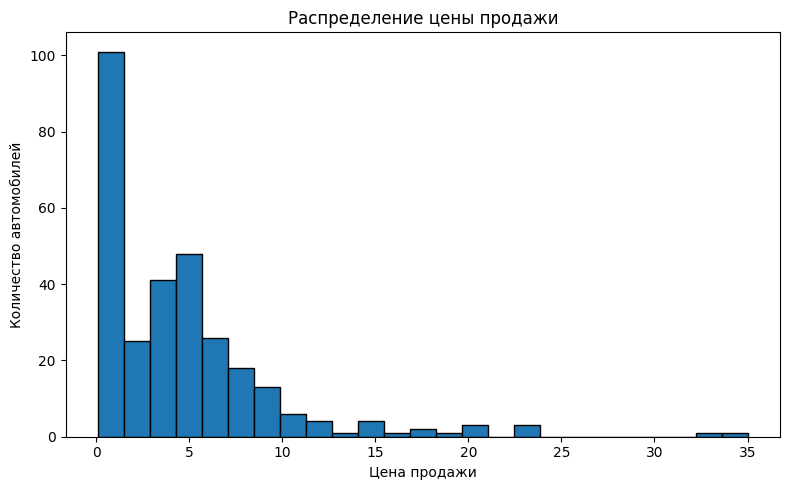

In [7]:
plt.figure(figsize=(8, 5))
plt.hist(df_clean["Selling_Price"], bins=25, edgecolor="black")
plt.xlabel("Цена продажи")
plt.ylabel("Количество автомобилей")
plt.title("Распределение цены продажи")
plt.tight_layout()
plt.savefig(eda_dir / "graph1_selling_price.png", dpi=130)
plt.show()

**Вывод:** большинство автомобилей имеет относительно невысокую цену продажи; дорогих машин мало. Распределение скошено вправо.

### График 2 - связь текущей цены и цены продажи

Точечный график удобен для сравнения двух числовых признаков.

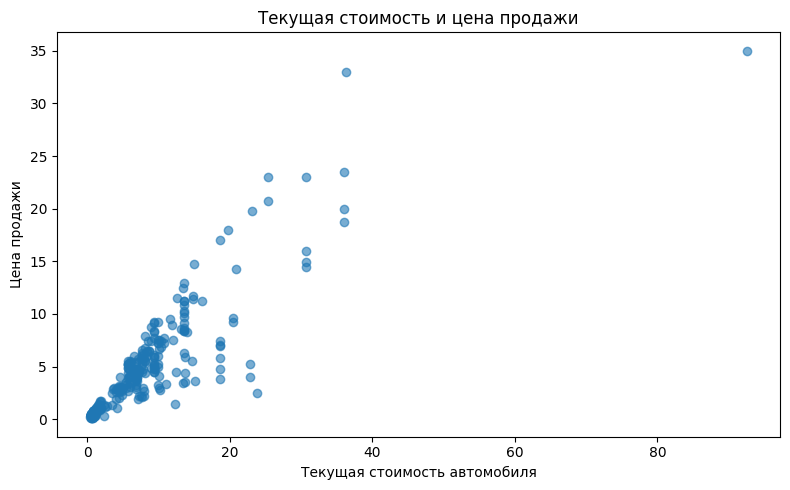

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(df_clean["Present_Price"], df_clean["Selling_Price"], alpha=0.6)
plt.xlabel("Текущая стоимость автомобиля")
plt.ylabel("Цена продажи")
plt.title("Текущая стоимость и цена продажи")
plt.tight_layout()
plt.savefig(eda_dir / "graph2_present_vs_selling.png", dpi=130)
plt.show()

**Вывод:** автомобили с более высокой `Present_Price` обычно продаются дороже. Это один из потенциально важных признаков для модели.

### График 3 - средняя цена продажи по году выпуска

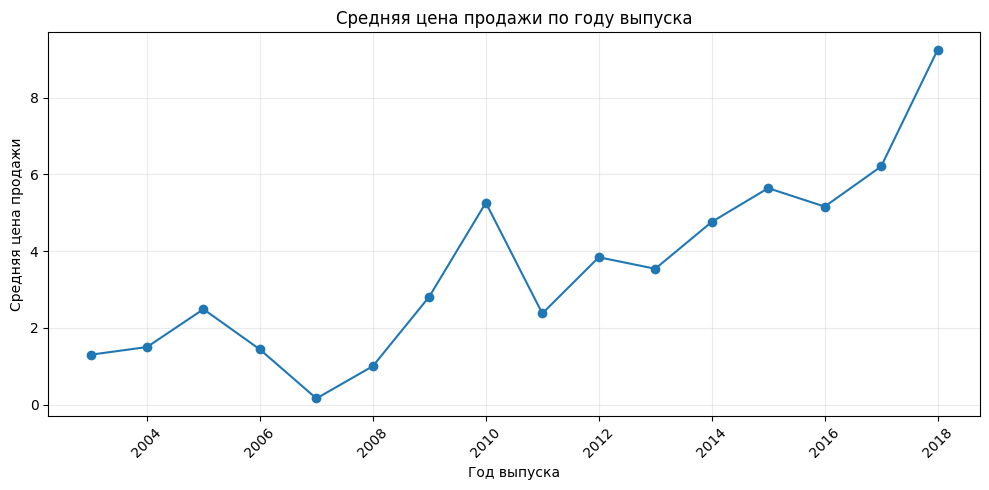

In [9]:
year_price = df_clean.groupby("Year")["Selling_Price"].mean()
plt.figure(figsize=(10, 5))
plt.plot(year_price.index, year_price.values, marker="o")
plt.xlabel("Год выпуска")
plt.ylabel("Средняя цена продажи")
plt.title("Средняя цена продажи по году выпуска")
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(eda_dir / "graph3_year.png", dpi=130)
plt.show()

**Вывод:** более новые автомобили в целом продаются дороже, но отдельные годы отличаются от общего тренда. На цену влияют и другие характеристики.

### График 4 - средняя цена по типу топлива

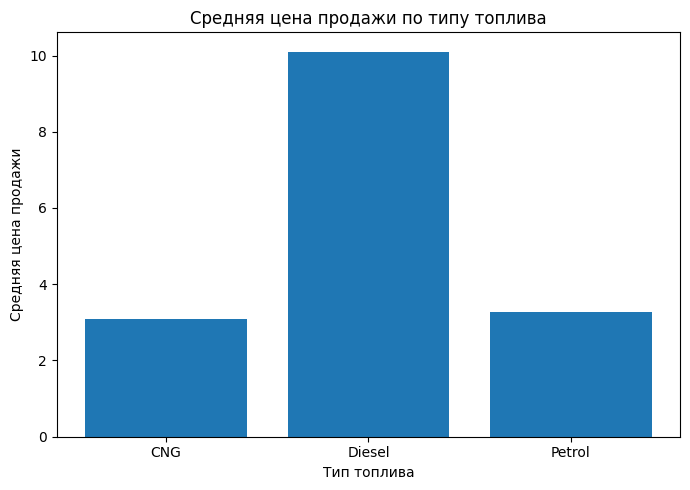

In [10]:
fuel_price = df_clean.groupby("Fuel_Type")["Selling_Price"].mean()
plt.figure(figsize=(7, 5))
plt.bar(fuel_price.index, fuel_price.values)
plt.xlabel("Тип топлива")
plt.ylabel("Средняя цена продажи")
plt.title("Средняя цена продажи по типу топлива")
plt.tight_layout()
plt.savefig(eda_dir / "graph4_fuel.png", dpi=130)
plt.show()

**Вывод:** в данном наборе данных дизельные автомобили в среднем дороже бензиновых и автомобилей на CNG. Это связь в данных, а не доказательство, что именно топливо определяет цену.

### График 5 - средняя цена по коробке передач

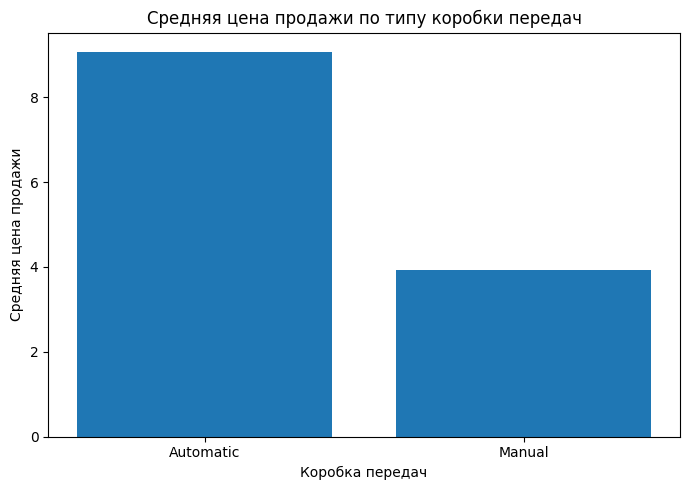

In [11]:
transmission_price = df_clean.groupby("Transmission")["Selling_Price"].mean()
plt.figure(figsize=(7, 5))
plt.bar(transmission_price.index, transmission_price.values)
plt.xlabel("Коробка передач")
plt.ylabel("Средняя цена продажи")
plt.title("Средняя цена продажи по типу коробки передач")
plt.tight_layout()
plt.savefig(eda_dir / "graph5_transmission.png", dpi=130)
plt.show()

**Вывод:** машины с автоматической коробкой в среднем дороже машин с механической коробкой в данном датасете.

### График 6 - интерактивная зависимость цены от пробега

В Plotly можно наводить курсор на точки, смотреть значения и приближать область. Интерактивный график сохраняется отдельно в HTML; его не нужно встраивать в вывод ячейки перед коммитом.

In [12]:
fig = px.scatter(
    df_clean,
    x="Driven_kms", y="Selling_Price",
    color="Fuel_Type", hover_data=["Car_Name", "Year", "Transmission"],
    labels={"Driven_kms": "Пробег (км)", "Selling_Price": "Цена продажи", "Fuel_Type": "Топливо"},
    title="Зависимость цены продажи от пробега"
)
fig.write_html(eda_dir / "graph6_interactive.html")
print("Интерактивный график сохранён в", eda_dir / "graph6_interactive.html")
# Чтобы открыть график, дважды нажмите на graph6_interactive.html в проводнике.
# Не используем fig.show(), чтобы не раздувать размер eda.ipynb.

Интерактивный график сохранён в /home/ubuntu/my_proj1/eda/graph6_interactive.html


**Вывод:** автомобили с похожим пробегом могут сильно различаться по цене. Поэтому пробег нужно рассматривать вместе с годом, текущей стоимостью и другими характеристиками.

## 4. Сохранение очищенного датасета

Очищенные данные будут нужны во второй лабораторной. Pickle сохраняет и значения, и типы столбцов. Файл данных не нужно отправлять на GitHub.

In [13]:
output_path = data_dir / "clean_dataset.pkl"
df_clean.to_pickle(output_path)
print("Сохранено:", output_path)
print("Количество строк:", len(df_clean))

Сохранено: /home/ubuntu/my_proj1/data/clean_dataset.pkl
Количество строк: 299


## 5. Итоговые выводы

1. В таблице было 301 наблюдение, пропусков нет, найдено и удалено 2 полных дубликата. Осталось 299 автомобилей.
2. Целевая переменная - `Selling_Price` (числовая), следовательно задача - регрессия.
3. Среди потенциально полезных признаков - `Present_Price`, `Year`, `Driven_kms`, `Fuel_Type`, `Transmission`.
4. Новые признаки на этапе EDA не создавались. Их можно сформировать в ЛР2.
5. Очищенный датасет сохранён в `data/clean_dataset.pkl`.

**Перед коммитом:** убедиться, что `.gitignore` исключает `*.csv`, `*.pkl`, `.venv*`; большие интерактивные выводы в самом блокноте не сохранять.